<a href="https://colab.research.google.com/github/mahamtaqi3-cloud/Cumulative-BMP-Signaling-and-Gene-Activation/blob/main/Cumulative_BMP_Signaling_and_Gene_Activation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Step 1: Setting up positions and time

In [15]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, accuracy_score
np.random.seed(0)

x = np.arange(0, 61, 5)       # distance from midline (microns)
t = np.arange(20, 61, 1.0)    # minutes after anaphase of nuclear cycle 13
X, T = np.meshgrid(x, t, indexing='ij')

Step 2: Simulating BMP signal: normal vs sog-like

In [16]:
def signal(genotype):
    s = (T - 20) / 40
    if genotype == 'WT':
        amp, width = 0.04 * s**2, 45 - 30 * s
    else:
        amp, width = 0.012 * s**2, 45 + 0 * s
    return amp * np.exp(-X**2 / (2 * width**2))

Step 3: Position-dependent restriction (stand-in for lateral regulation)

In [17]:
def gate(on):
    return 1 / (1 + np.exp((X - 45) / 4)) if on else np.ones_like(X)

Step 4: Simulating nuclei switching on

In [18]:
def make_nuclei(genotype, spatial_gate, k, n_per_pos=40):
    c = signal(genotype)
    H = np.cumsum(k * c * gate(spatial_gate), axis=1)
    rows = []
    for i in range(len(x)):
        for _ in range(n_per_pos):
            E = np.random.exponential(1.0)
            for j in range(len(t)):
                rows.append((c[i, j], np.cumsum(c[i])[j], x[i], H[i, j] >= E))
    d = np.array(rows, dtype=float)
    return d[:, 0:1], d[:, 1:2], d[:, 2:3], d[:, 3].astype(int)

Step 5: Training and test: current vs total signal

In [19]:
inst, integ, pos, y = make_nuclei('WT', False, 60)
idx = np.random.permutation(len(y)); cut = int(0.7 * len(y))
tr, te = idx[:cut], idx[cut:]

for name, F in [('instantaneous', inst), ('integrated', integ)]:
    m = LogisticRegression(max_iter=2000).fit(F[tr] / F.max(), y[tr])
    p = m.predict_proba(F[te] / F.max())[:, 1]
    print(name, 'accuracy', round(accuracy_score(y[te], p > .5), 3),
          'AUC', round(roc_auc_score(y[te], p), 3))

instantaneous accuracy 0.806 AUC 0.892
integrated accuracy 0.872 AUC 0.955


Step 6: Transfer test: normal-trained model applied to sog-like embryos with restriction

In [20]:
m = LogisticRegression(max_iter=2000).fit(integ / integ.max(), y)
_, integ2, _, y2 = make_nuclei('sog', True, 150)
p2 = m.predict_proba(integ2 / integ.max())[:, 1]
print('WT -> sog+gate accuracy', round(accuracy_score(y2, p2 > .5), 3),
      'AUC', round(roc_auc_score(y2, p2), 3))

WT -> sog+gate accuracy 0.803 AUC 0.912


Step 7: Summary Plot

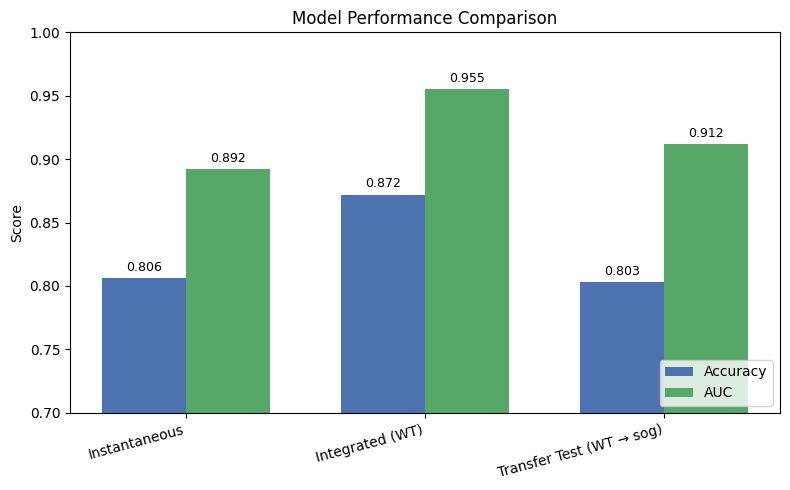

In [21]:
import matplotlib.pyplot as plt
import numpy as np

# Performance metrics from our evaluation and transfer tests
models = ['Instantaneous', 'Integrated (WT)', 'Transfer Test (WT → sog)']
accuracy = [0.806, 0.872, 0.803]
auc = [0.892, 0.955, 0.912]

x = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
rects1 = ax.bar(x - width/2, accuracy, width, label='Accuracy', color='#4c72b0')
rects2 = ax.bar(x + width/2, auc, width, label='AUC', color='#55a868')

ax.set_ylabel('Score')
ax.set_title('Model Performance Comparison')
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=15, ha='right')
ax.legend(loc='lower right')
ax.set_ylim(0.7, 1.0)

# Add values on top of bars
for bar in rects1 + rects2:
    height = bar.get_height()
    ax.annotate(f'{height:.3f}',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3),  # 3 points vertical offset
                textcoords="offset points",
                ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()